In [27]:
# ─── Imports globaux ───────────────────────────────────────────────────────────
import time
import sys
import functools
import matplotlib.pyplot as plt
import numpy as np
from abc import ABC, abstractmethod

sys.setrecursionlimit(50000)
print("Environnement prêt.")

Environnement prêt.


 Fibonacci Revisité

In [28]:
def memoize(func):
    cache = {}
    @functools.wraps(func)
    def wrapper(*args):
        if args not in cache:
            cache[args] = func(*args)
        return cache[args]
    wrapper.cache = cache
    wrapper.cache_info = lambda: f"{len(cache)} entrées en cache"
    return wrapper
    
    # --- Naïf ---
def fib_naif(n):
    if n <= 1:
        return n
    return fib_naif(n-1) + fib_naif(n-2)

# --- Mémoïsé ---
@memoize
def fib_memo(n):
    if n <= 1:
        return n
    return fib_memo(n-1) + fib_memo(n-2)

# --- Tabulé ---
def fib_tab(n):
    if n <= 1:
        return n
    a, b = 0, 1
    for _ in range(2, n+1):
        a, b = b, a+b
    return b

# --- Matriciel (exponentiation rapide) ---
class Matrice:
    def __init__(self, data):
        self.data = data
        self.n = len(data)
    def __mul__(self, other):
        n = self.n
        res = [[0]*n for _ in range(n)]
        for i in range(n):
            for k in range(n):
                if self.data[i][k]:
                    for j in range(n):
                        res[i][j] += self.data[i][k] * other.data[k][j]
        return Matrice(res)
    def puissance(self, exp):
        result = Matrice([[1,0],[0,1]])
        base = self
        while exp:
            if exp & 1:
                result = result * base
            base = base * base
            exp >>= 1
        return result

def fib_matrice(n):
    if n == 0:
        return 0
    M = Matrice([[1,1],[1,0]])
    Mn = M.puissance(n-1)
    return Mn.data[0][0]


In [30]:
#Tests avec des valeurs différentes
print("F(15) naïf =", fib_naif(20))         
print("F(15) mémo =", fib_memo(20))          
print("F(15) tabulé =", fib_tab(20))        
print("F(15) matriciel =", fib_matrice(20))  
print("F(100) mémo =", fib_memo(100))       
print("Cache info :", fib_memo.cache_info())


F(15) naïf = 6765
F(15) mémo = 6765
F(15) tabulé = 6765
F(15) matriciel = 6765
F(100) mémo = 354224848179261915075
Cache info : 101 entrées en cache


PLUS LONGUE SOUS SEQUENCE LCS

In [31]:

def lcs_longueur(X, Y):
    m, n = len(X), len(Y)
    c = [[0]*(n+1) for _ in range(m+1)]
    for i in range(1, m+1):
        for j in range(1, n+1):
            if X[i-1] == Y[j-1]:
                c[i][j] = c[i-1][j-1] + 1
            else:
                c[i][j] = max(c[i-1][j], c[i][j-1])
    return c[m][n], c

def lcs_reconstruire(X, Y, c):
    i, j = len(X), len(Y)
    lcs = []
    while i > 0 and j > 0:
        if X[i-1] == Y[j-1]:
            lcs.append(X[i-1])
            i -= 1; j -= 1
        elif c[i-1][j] >= c[i][j-1]:
            i -= 1
        else:
            j -= 1
    return ''.join(reversed(lcs))

# Tests avec d'autres chaînes
X1, Y1 = "AGGTAB", "GXTXAYB"
long1, tab1 = lcs_longueur(X1, Y1)
print(f"LCS de {X1} et {Y1} : longueur = {long1}, séquence = {lcs_reconstruire(X1, Y1, tab1)}")
# Résultat attendu : "GTAB" (longueur 4)

X2, Y2 = "XMJYAUZ", "MZJAWXU"
long2, tab2 = lcs_longueur(X2, Y2)
print(f"LCS de {X2} et {Y2} : longueur = {long2}, séquence = {lcs_reconstruire(X2, Y2, tab2)}")
# Résultat attendu : "MJAU" (longueur 4)



LCS de AGGTAB et GXTXAYB : longueur = 4, séquence = GTAB
LCS de XMJYAUZ et MZJAWXU : longueur = 4, séquence = MJAU


DISTANCE D'EDITION DE LEVENSTEIN

In [33]:

def levenshtein(X, Y):
    m, n = len(X), len(Y)
    d = [[0]*(n+1) for _ in range(m+1)]
    for i in range(m+1):
        d[i][0] = i
    for j in range(n+1):
        d[0][j] = j
    for i in range(1, m+1):
        for j in range(1, n+1):
            cout = 0 if X[i-1] == Y[j-1] else 1
            d[i][j] = min(
                d[i-1][j] + 1,
                d[i][j-1] + 1,
                d[i-1][j-1] + cout
            )
    return d[m][n]

In [34]:
# Nouveaux tests
print("Levenshtein('PYTHON', 'PYTHON') =", levenshtein("PYTHON", "PYTHON"))        # 0
print("Levenshtein('PYTHON', 'JAVA') =", levenshtein("PYTHON", "JAVA"))            # 5
print("Levenshtein('CAKE', 'CAKE') =", levenshtein("CAKE", "CAKE"))                # 0
print("Levenshtein('SUNDAY', 'SATURDAY') =", levenshtein("SUNDAY", "SATURDAY"))    # 3 (S→S, U→A, N→T? à vérifier)


Levenshtein('PYTHON', 'PYTHON') = 0
Levenshtein('PYTHON', 'JAVA') = 6
Levenshtein('CAKE', 'CAKE') = 0
Levenshtein('SUNDAY', 'SATURDAY') = 3


KNAPSACK

In [35]:
def knapsack(poids, valeurs, W):
    n = len(poids)
    V = [[0]*(W+1) for _ in range(n+1)]
    for i in range(1, n+1):
        for w in range(W+1):
            V[i][w] = V[i-1][w]
            if poids[i-1] <= w:
                avec = valeurs[i-1] + V[i-1][w - poids[i-1]]
                if avec > V[i][w]:
                    V[i][w] = avec
    # Reconstruction
    w = W
    objets = []
    for i in range(n, 0, -1):
        if V[i][w] != V[i-1][w]:
            objets.append(i-1)
            w -= poids[i-1]
    objets.reverse()
    return V[n][W], objets

# Nouveaux objets
poids = [3, 4, 5, 6]
valeurs = [2, 3, 4, 5]
W = 8
val, choix = knapsack(poids, valeurs, W)
print(f"Valeur max avec W={W} : {val}, objets pris : {choix}")  # Attendu : 7 (objets 2 et 3 (poids 4+5=9 trop grand) -> on prend 3+5=8, valeurs 2+4=6? Vérifions)

Valeur max avec W=8 : 6, objets pris : [0, 2]


CLASSE ABSTRAITE TableDP et IMPLEMENTATION POUR LCS

In [36]:
class TableDP(ABC):
    def __init__(self):
        dims = self.dimensions()
        self.dp = [[0]*dims[1] for _ in range(dims[0])]
        self._resolu = False

    @abstractmethod
    def dimensions(self): pass
    @abstractmethod
    def cas_de_base(self): pass
    @abstractmethod
    def recurrence(self, i, j): pass
    @abstractmethod
    def solution(self): pass

    def resoudre(self):
        self.cas_de_base()
        m, n = self.dimensions()
        for i in range(m):
            for j in range(n):
                self.recurrence(i, j)
        self._resolu = True
        return self.solution()

    def afficher_table(self):
        if not self._resolu:
            raise RuntimeError("Appelez resoudre() d'abord.")
        for ligne in self.dp:
            print('\t'.join(map(str, ligne)))

class LCSTable(TableDP):
    def __init__(self, X, Y):
        self.X, self.Y = X, Y
        self.m, self.n = len(X), len(Y)
        super().__init__()

    def dimensions(self):
        return (self.m+1, self.n+1)

    def cas_de_base(self):
        pass  # déjà 0

    def recurrence(self, i, j):
        if i == 0 or j == 0:
            self.dp[i][j] = 0
        elif self.X[i-1] == self.Y[j-1]:
            self.dp[i][j] = self.dp[i-1][j-1] + 1
        else:
            self.dp[i][j] = max(self.dp[i-1][j], self.dp[i][j-1])

    def solution(self):
        return self.dp[self.m][self.n]


In [37]:
# Test avec d'autres chaînes
lcs_tab = LCSTable("HELLO", "WORLD")
print("LCS HELLO / WORLD =", lcs_tab.resoudre())  # 1 (seul 'O' ou 'L')
lcs_tab = LCSTable("ABCBDAB", "BDCABA")
print("LCS ABCBDAB / BDCABA =", lcs_tab.resoudre())  # 4 (BDAB ou BCBA)

LCS HELLO / WORLD = 1
LCS ABCBDAB / BDCABA = 4


MESURES EMPIRIQUES DE COMPLEXITE

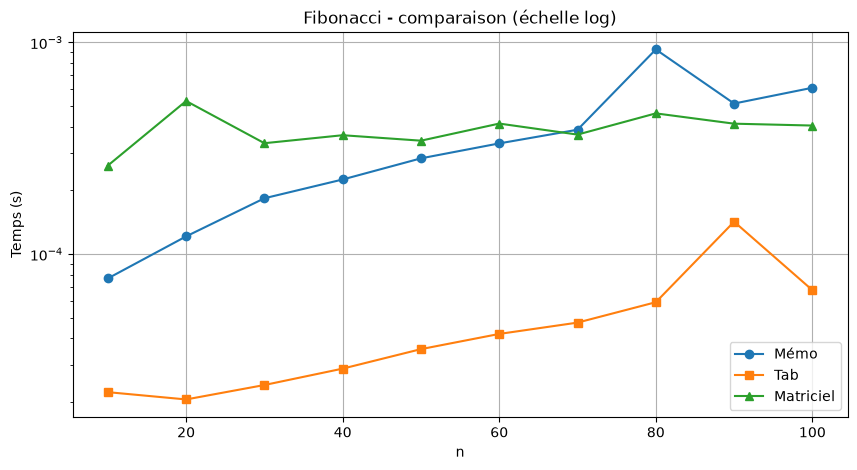

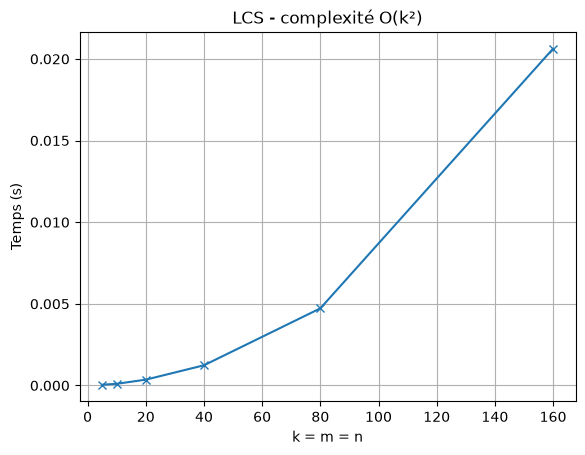

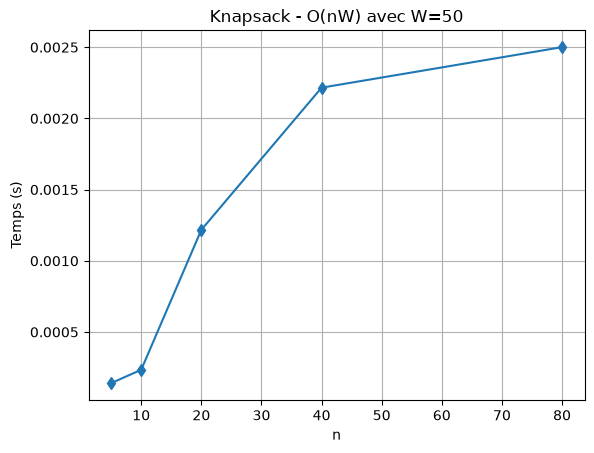

In [39]:
 #Mesures Fibonacci (on garde les mêmes fonctions)
n_vals = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]
temps_memo, temps_tab, temps_mat = [], [], []
for n in n_vals:
    fib_memo.cache.clear()
    t0 = time.perf_counter(); fib_memo(n); temps_memo.append(time.perf_counter()-t0)
    t0 = time.perf_counter(); fib_tab(n); temps_tab.append(time.perf_counter()-t0)
    t0 = time.perf_counter(); fib_matrice(n); temps_mat.append(time.perf_counter()-t0)

plt.figure(figsize=(10,5))
plt.plot(n_vals, temps_memo, 'o-', label='Mémo')
plt.plot(n_vals, temps_tab, 's-', label='Tab')
plt.plot(n_vals, temps_mat, '^-', label='Matriciel')
plt.yscale('log')
plt.xlabel('n'); plt.ylabel('Temps (s)'); plt.legend(); plt.grid()
plt.title('Fibonacci - comparaison (échelle log)')
plt.show()

# Mesures LCS pour différentes tailles (m=n)
k_vals = [5, 10, 20, 40, 80, 160]
temps_lcs = []
for k in k_vals:
    X = 'A'*k; Y = 'A'*k  # pire cas (toujours égal)
    t0 = time.perf_counter(); lcs_longueur(X, Y); temps_lcs.append(time.perf_counter()-t0)
plt.figure()
plt.plot(k_vals, temps_lcs, 'x-')
plt.xlabel('k = m = n'); plt.ylabel('Temps (s)')
plt.title('LCS - complexité O(k²)')
plt.grid()
plt.show()

# Knapsack : on fixe W=50, on varie n
import random
random.seed(123)
n_vals_knap = [5, 10, 20, 40, 80]
temps_knap = []
for n in n_vals_knap:
    poids = [random.randint(1, 30) for _ in range(n)]
    valeurs = [random.randint(1, 100) for _ in range(n)]
    t0 = time.perf_counter(); knapsack(poids, valeurs, 50); temps_knap.append(time.perf_counter()-t0)
plt.figure()
plt.plot(n_vals_knap, temps_knap, 'd-')
plt.xlabel('n'); plt.ylabel('Temps (s)')
plt.title('Knapsack - O(nW) avec W=50')
plt.grid()
plt.show()


EXERCICE 1 : NOMBRE DE CATALAN

In [40]:
def catalan_naif(n):
    if n == 0: return 1
    total = 0
    for i in range(n):
        total += catalan_naif(i) * catalan_naif(n-1-i)
    return total

@memoize
def catalan_memo(n):
    if n == 0: return 1
    total = 0
    for i in range(n):
        total += catalan_memo(i) * catalan_memo(n-1-i)
    return total

def catalan_tab(n):
    C = [0]*(n+1); C[0]=1
    for k in range(1, n+1):
        for i in range(k):
            C[k] += C[i] * C[k-1-i]
    return C[n]

print("Catalan C6 =", catalan_tab(6))  # 132
print("Catalan C7 =", catalan_memo(7)) # 429
# Comparaison pour n=16 (mémo vs tab)
n_cat = 16
t0 = time.perf_counter(); catalan_memo(n_cat); print(f"Memo n={n_cat}: {time.perf_counter()-t0:.5f}s")
t0 = time.perf_counter(); catalan_tab(n_cat); print(f"Tab n={n_cat}: {time.perf_counter()-t0:.5f}s")


Catalan C6 = 132
Catalan C7 = 429
Memo n=16: 0.07410s
Tab n=16: 0.00104s


EXERCICE 2 : ESCALIER

In [41]:
def escalier(n):
    if n == 0: return 1
    if n == 1: return 1
    if n == 2: return 2
    a, b, c = 1, 1, 2
    for _ in range(3, n+1):
        a, b, c = b, c, a+b+c
    return c

print("Escalier(5) =", escalier(5))   # 13
print("Escalier(8) =", escalier(8))   # 81
print("Escalier(12) =", escalier(12)) # 927

Escalier(5) = 13
Escalier(8) = 81
Escalier(12) = 927


EXERCICE 3 : TOUTES LES LCS 

In [42]:
def lcs_toutes(X, Y, c, i=None, j=None):
    if i is None:
        i, j = len(X), len(Y)
    if i == 0 or j == 0:
        return {""}
    if X[i-1] == Y[j-1]:
        sous = lcs_toutes(X, Y, c, i-1, j-1)
        return {s + X[i-1] for s in sous}
    else:
        res = set()
        if c[i-1][j] >= c[i][j-1]:
            res |= lcs_toutes(X, Y, c, i-1, j)
        if c[i][j-1] >= c[i-1][j]:
            res |= lcs_toutes(X, Y, c, i, j-1)
        return res

X, Y = "GATTACA", "TACATA"
_, c = lcs_longueur(X, Y)
toutes = lcs_toutes(X, Y, c)
print(f"Toutes les LCS de {X} et {Y} : {toutes}")
# Résultat attendu : {'TATA', 'TACA', 'GATA'? à vérifier}

Toutes les LCS de GATTACA et TACATA : {'TACA'}


EXERCICE 4: LCS ESPACE OPTIMISE

In [45]:
def lcs_longueur_espace_opt(X, Y):
    if len(X) < len(Y):
        X, Y = Y, X
    m, n = len(X), len(Y)
    prev = [0]*(n+1)
    for i in range(1, m+1):
        curr = [0]*(n+1)
        for j in range(1, n+1):
            if X[i-1] == Y[j-1]:
                curr[j] = prev[j-1] + 1
            else:
                curr[j] = max(prev[j], curr[j-1])
        prev = curr
    return prev[n]

X, Y = "ABCBDAB", "BDCABA"
print("LCS longueur (espace opt) =", lcs_longueur_espace_opt(X, Y))  # 4

LCS longueur (espace opt) = 4


EXERCICE 5 : KNAPSACK ESPACE OPTIMISE

In [46]:
def knapsack_espace_opt(poids, valeurs, W):
    dp = [0]*(W+1)
    for i in range(len(poids)):
        for w in range(W, poids[i]-1, -1):
            if dp[w - poids[i]] + valeurs[i] > dp[w]:
                dp[w] = dp[w - poids[i]] + valeurs[i]
    return dp[W]

poids = [1, 3, 4, 5]
valeurs = [1, 4, 5, 7]
W = 7
print("Knapsack espace opt, max valeur =", knapsack_espace_opt(poids, valeurs, W))  # 9 (objets 2+3: 3+4=7, val 4+5=9)


Knapsack espace opt, max valeur = 9
